In [ ]:
!pip install -q pyarrow openpyxl

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
file_path = "/content/ThreatLens_Cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (2231806, 78)


In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'D

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


In [ ]:
df.columns = df.columns.str.strip()

print("Column names cleaned.")

Column names cleaned.


In [ ]:
print("Target column exists:", "Label" in df.columns)

print("\nTarget classes:")
print(df["Label"].value_counts())

Target column exists: True

Target classes:
Label
Benign                        1895314
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=["Label"])
y = df["Label"]

print("Features X shape:", X.shape)
print("Target y shape:", y.shape)

print("\nNumber of input features:", X.shape[1])
print("Number of target classes:", y.nunique())

Features X shape: (2231806, 77)
Target y shape: (2231806,)

Number of input features: 77
Number of target classes: 15


In [ ]:
print(X.dtypes.value_counts())

int64      53
float64    24
Name: count, dtype: int64


In [ ]:
print("\nObject/Categorical columns:")
print(X.select_dtypes(include=["object"]).columns.tolist())


Object/Categorical columns:
[]


In [ ]:
X = X.replace([np.inf, -np.inf], np.nan)

print("Infinite values replaced with NaN.")

Infinite values replaced with NaN.


In [ ]:
print("Total missing values:", X.isnull().sum().sum())

Total missing values: 0


In [ ]:
numeric_columns = X.select_dtypes(include=np.number).columns

for column in numeric_columns:
    X[column] = X[column].fillna(X[column].median())

print("Missing numerical values handled.")

Missing numerical values handled.


FEATURE EXTRACTION

In [ ]:
if "Total Fwd Packets" in X.columns and "Total Backward Packets" in X.columns:
    X["Total_Packets_Extracted"] = (
        X["Total Fwd Packets"] +
        X["Total Backward Packets"]
    )

In [ ]:
if "Total Length of Fwd Packets" in X.columns and "Total Length of Bwd Packets" in X.columns:
    X["Total_Bytes_Extracted"] = (
        X["Total Length of Fwd Packets"] +
        X["Total Length of Bwd Packets"]
    )

In [ ]:
if (
    "Total Length of Fwd Packets" in X.columns and
    "Total Length of Bwd Packets" in X.columns and
    "Total Fwd Packets" in X.columns and
    "Total Backward Packets" in X.columns
):

    total_bytes = (
        X["Total Length of Fwd Packets"] +
        X["Total Length of Bwd Packets"]
    )

    total_packets = (
        X["Total Fwd Packets"] +
        X["Total Backward Packets"]
    )

    X["Bytes_Per_Packet_Extracted"] = (
        total_bytes / total_packets.replace(0, np.nan)
    )

In [ ]:
X = X.replace([np.inf, -np.inf], np.nan)

numeric_columns = X.select_dtypes(include=np.number).columns

for column in numeric_columns:
    X[column] = X[column].fillna(X[column].median())

print("Feature extraction completed.")
print("New number of features:", X.shape[1])

Feature extraction completed.
New number of features: 78


REMOVE CONSTANT FEATURES

In [ ]:
constant_features = [
    column for column in X.columns
    if X[column].nunique() <= 1
]

print("Constant features:")
print(constant_features)

Constant features:
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [ ]:
if constant_features:
    X = X.drop(columns=constant_features)

print("Shape after removing constant features:", X.shape)

Shape after removing constant features: (2231806, 70)


SPLIT TRAINING AND TESTING 80:20

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (1785444, 70)
Testing data: (446362, 70)
Training labels: (1785444,)
Testing labels: (446362,)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Target classes:")
for number, label in enumerate(label_encoder.classes_):
    print(number, "→", label)

Target classes:
0 → Benign
1 → Bot
2 → DDoS
3 → DoS GoldenEye
4 → DoS Hulk
5 → DoS Slowhttptest
6 → DoS slowloris
7 → FTP-Patator
8 → Heartbleed
9 → Infiltration
10 → PortScan
11 → SSH-Patator
12 → Web Attack � Brute Force
13 → Web Attack � Sql Injection
14 → Web Attack � XSS


In [ ]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns)

Numerical features: 70
Categorical features: 0

Categorical columns:
[]


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

Training matrix shape: (1785444, 70)
Testing matrix shape: (446362, 70)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFirst 20 features:")
print(feature_names[:20])

Total transformed features: 70

First 20 features:
['numeric__Protocol' 'numeric__Flow Duration' 'numeric__Total Fwd Packets'
 'numeric__Total Backward Packets' 'numeric__Fwd Packets Length Total'
 'numeric__Bwd Packets Length Total' 'numeric__Fwd Packet Length Max'
 'numeric__Fwd Packet Length Min' 'numeric__Fwd Packet Length Mean'
 'numeric__Fwd Packet Length Std' 'numeric__Bwd Packet Length Max'
 'numeric__Bwd Packet Length Min' 'numeric__Bwd Packet Length Mean'
 'numeric__Bwd Packet Length Std' 'numeric__Flow Bytes/s'
 'numeric__Flow Packets/s' 'numeric__Flow IAT Mean'
 'numeric__Flow IAT Std' 'numeric__Flow IAT Max' 'numeric__Flow IAT Min']


FEATURE SELECTION

In [ ]:
# ============================================
# TASK 5 - STEP 17A
# Create a sample for feature selection
# ============================================

SAMPLE_SIZE = 50000

# Use at most 50,000 rows
if X_train.shape[0] > SAMPLE_SIZE:

    random_state = np.random.RandomState(42)

    sample_indices = random_state.choice(
        X_train.shape[0],
        SAMPLE_SIZE,
        replace=False
    )

else:

    sample_indices = np.arange(X_train.shape[0])

# Select sampled rows
X_mi = X_train_processed[sample_indices]
y_mi = y_train_encoded[sample_indices]

print("Original training rows:", X_train.shape[0])
print("Rows used for feature selection:", X_mi.shape[0])
print("Number of features:", X_mi.shape[1])

Original training rows: 1785444
Rows used for feature selection: 50000
Number of features: 70


In [ ]:
# ============================================
# TASK 5 - STEP 17B
# Calculate Mutual Information
# ============================================

from sklearn.feature_selection import mutual_info_classif

print("Calculating Mutual Information...")
print("Please wait...")

mi_scores = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=42
)

print("Mutual Information calculation completed!")

Calculating Mutual Information...
Please wait...
Mutual Information calculation completed!


In [ ]:
# ============================================
# TASK 5 - STEP 17C
# Rank features by Mutual Information
# ============================================

mi_df = pd.DataFrame({
    "Feature": feature_names,
    "Mutual_Information": mi_scores
})

mi_df = mi_df.sort_values(
    by="Mutual_Information",
    ascending=False
).reset_index(drop=True)

print("Top 20 features:")
display(mi_df.head(20))

Top 20 features:


,Feature,Mutual_Information
0,numeric__Avg Packet Size,0.471516
1,numeric__Bwd Packet Length Mean,0.445730
2,numeric__Avg Bwd Segment Size,0.445312
3,numeric__Subflow Bwd Bytes,0.442279
4,numeric__Bwd Packets Length Total,0.440425
5,numeric__Packet Length Mean,0.432300
6,numeric__Packet Length Std,0.423291
7,numeric__Packet Length Variance,0.421038
8,numeric__Packet Length Max,0.416586
9,numeric__Bwd Packet Length Max,0.410686


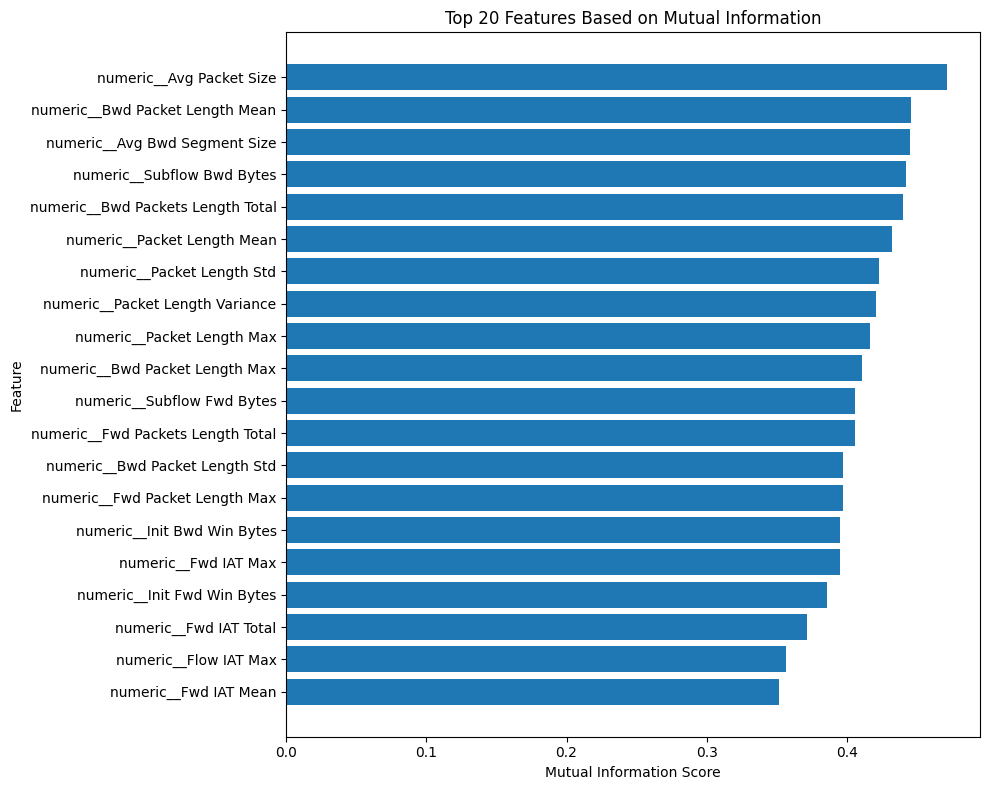

In [ ]:
# ============================================
# TASK 5 - STEP 18
# Visualize top 20 selected features
# ============================================

top_mi = mi_df.head(20).sort_values(
    by="Mutual_Information",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_mi["Feature"],
    top_mi["Mutual_Information"]
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.title("Top 20 Features Based on Mutual Information")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# TASK 5 - STEP 19
# Select Top 20 Features
# ============================================

TOP_K = 20

selected_features = mi_df.head(TOP_K)["Feature"].tolist()

print("Selected features for ML model:")

for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

Selected features for ML model:
1. numeric__Avg Packet Size
2. numeric__Bwd Packet Length Mean
3. numeric__Avg Bwd Segment Size
4. numeric__Subflow Bwd Bytes
5. numeric__Bwd Packets Length Total
6. numeric__Packet Length Mean
7. numeric__Packet Length Std
8. numeric__Packet Length Variance
9. numeric__Packet Length Max
10. numeric__Bwd Packet Length Max
11. numeric__Subflow Fwd Bytes
12. numeric__Fwd Packets Length Total
13. numeric__Bwd Packet Length Std
14. numeric__Fwd Packet Length Max
15. numeric__Init Bwd Win Bytes
16. numeric__Fwd IAT Max
17. numeric__Init Fwd Win Bytes
18. numeric__Fwd IAT Total
19. numeric__Flow IAT Max
20. numeric__Fwd IAT Mean


In [ ]:
# ============================================
# TASK 5 - STEP 20
# Find selected feature positions
# ============================================

selected_indices = [
    list(feature_names).index(feature)
    for feature in selected_features
]

print("Number of selected features:", len(selected_indices))
print("Feature indices:", selected_indices)

Number of selected features: 20
Feature indices: [50, 12, 52, 56, 5, 38, 39, 40, 37, 10, 54, 4, 13, 6, 58, 23, 57, 20, 18, 21]


In [ ]:
# ============================================
# TASK 5 - STEP 21
# Create final ML feature matrices
# ============================================

X_train_final = X_train_processed[:, selected_indices]
X_test_final = X_test_processed[:, selected_indices]

print("Final training feature matrix:")
print("X_train_final:", X_train_final.shape)

print("\nFinal testing feature matrix:")
print("X_test_final:", X_test_final.shape)

print("\nTraining target:")
print("y_train:", y_train_encoded.shape)

print("\nTesting target:")
print("y_test:", y_test_encoded.shape)

Final training feature matrix:
X_train_final: (1785444, 20)

Final testing feature matrix:
X_test_final: (446362, 20)

Training target:
y_train: (1785444,)

Testing target:
y_test: (446362,)


In [ ]:
# ============================================
# TASK 5 - STEP 22
# Random Forest Feature Importance
# ============================================

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("Training Random Forest for feature importance...")

rf.fit(
    X_train_final,
    y_train_encoded
)

print("Random Forest completed!")

Training Random Forest for feature importance...
Random Forest completed!


In [ ]:
# ============================================
# TASK 5 - STEP 23
# Calculate feature importance
# ============================================

rf_importance = pd.DataFrame({
    "Feature": selected_features,
    "Importance": rf.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(rf_importance)

,Feature,Importance
0,numeric__Init Bwd Win Bytes,0.085149
1,numeric__Fwd IAT Mean,0.082400
2,numeric__Flow IAT Max,0.075307
3,numeric__Fwd Packet Length Max,0.070581
4,numeric__Fwd IAT Total,0.067928
5,numeric__Fwd IAT Max,0.065516
6,numeric__Init Fwd Win Bytes,0.061474
7,numeric__Fwd Packets Length Total,0.047254
8,numeric__Bwd Packets Length Total,0.047113
9,numeric__Avg Bwd Segment Size,0.043977


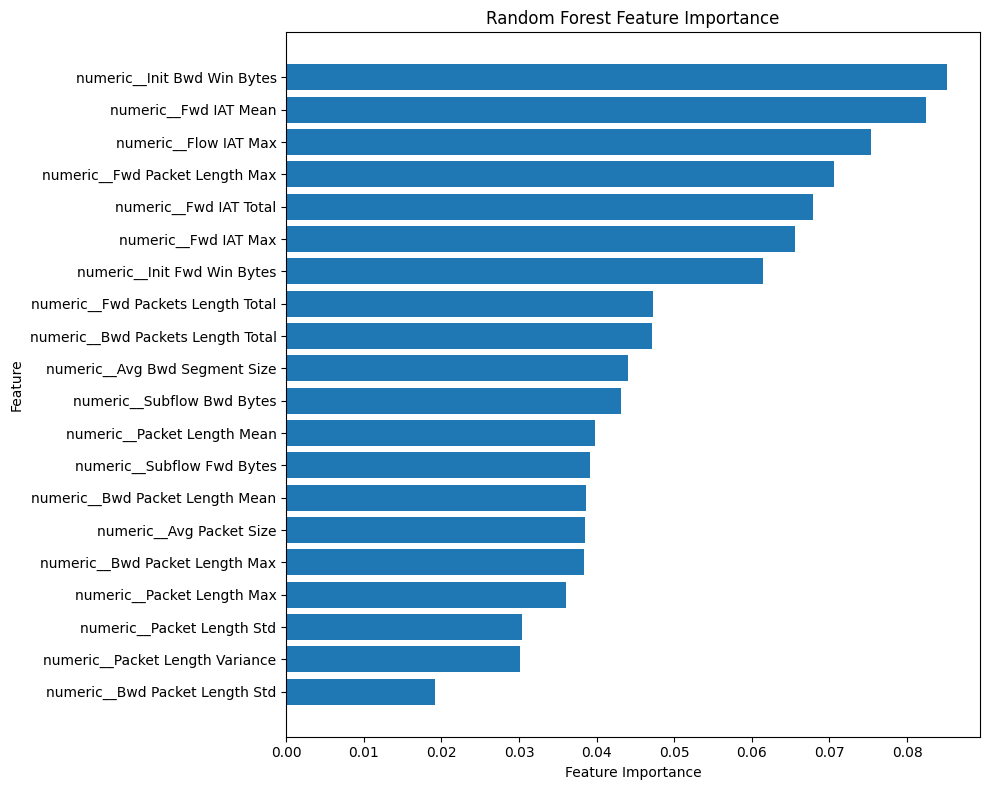

In [ ]:
# ============================================
# TASK 5 - STEP 24
# Feature importance visualization
# ============================================

plot_importance = rf_importance.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# TASK 5 - STEP 25
# Combine feature selection results
# ============================================

feature_analysis = mi_df.merge(
    rf_importance,
    on="Feature",
    how="left"
)

feature_analysis = feature_analysis.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_analysis)

,Feature,Mutual_Information,Importance
0,numeric__Init Bwd Win Bytes,0.395445,0.085149
1,numeric__Fwd IAT Mean,0.351571,0.082400
2,numeric__Flow IAT Max,0.356770,0.075307
3,numeric__Fwd Packet Length Max,0.397198,0.070581
4,numeric__Fwd IAT Total,0.371280,0.067928
...,...,...,...
65,numeric__SYN Flag Count,0.009749,NaN
66,numeric__RST Flag Count,0.000932,NaN
67,numeric__Fwd URG Flags,0.000000,NaN
68,numeric__CWE Flag Count,0.000000,NaN


In [ ]:
# ============================================
# TASK 5 - STEP 26
# Save final ML-ready datasets
# ============================================

X_train_final_df = pd.DataFrame(
    X_train_final,
    columns=selected_features
)

X_test_final_df = pd.DataFrame(
    X_test_final,
    columns=selected_features
)

y_train_final_df = pd.DataFrame({
    "Label": y_train_encoded
})

y_test_final_df = pd.DataFrame({
    "Label": y_test_encoded
})

X_train_final_df.to_csv(
    "/content/ThreatLens_X_train.csv",
    index=False
)

X_test_final_df.to_csv(
    "/content/ThreatLens_X_test.csv",
    index=False
)

y_train_final_df.to_csv(
    "/content/ThreatLens_y_train.csv",
    index=False
)

y_test_final_df.to_csv(
    "/content/ThreatLens_y_test.csv",
    index=False
)

feature_analysis.to_csv(
    "/content/ThreatLens_Feature_Importance.csv",
    index=False
)

print("All Task 5 files saved successfully!")

All Task 5 files saved successfully!
